In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

In [3]:
pd.set_option("display.max_columns", None)

In [14]:
import os

print(os.getcwd())

d:\B.tech MATERIALS\SEM-7\Epinions\notebooks


In [16]:
with open("../epinions/epinions/rating.txt", "r") as f:
    for _ in range(5):
        print(f.readline())

139431556	591156	5	0	2001/01/10		1	2518365

139431556	1312460676	5	0	2001/01/10		1	2518365

139431556	204358	5	0	2001/01/10		1	2518365

139431556	368725	5	0	2001/01/10		1	2518365

139431556	277629	5	0	2001/01/10		1	2518365



In [22]:
import pandas as pd

rows = []

with open("../epinions/epinions/rating.txt", "r") as f:
    for line in f:
        parts = line.split()

        if len(parts) == 7:
            object_id, member_id, rating, status, creation, type_, vertical = parts
            last_modified = None

        elif len(parts) == 8:
            object_id, member_id, rating, status, creation, last_modified, type_, vertical = parts

        else:
            continue

        rows.append([
            object_id,
            member_id,
            rating,
            status,
            creation,
            last_modified,
            type_,
            vertical
        ])

ratings = pd.DataFrame(
    rows,
    columns=[
        "OBJECT_ID",
        "MEMBER_ID",
        "RATING",
        "STATUS",
        "CREATION",
        "LAST_MODIFIED",
        "TYPE",
        "VERTICAL_ID"
    ]
)

In [23]:
ratings.head()

,OBJECT_ID,MEMBER_ID,RATING,STATUS,CREATION,LAST_MODIFIED,TYPE,VERTICAL_ID
0,139431556,591156,5,0,2001/01/10,None,1,2518365
1,139431556,1312460676,5,0,2001/01/10,None,1,2518365
2,139431556,204358,5,0,2001/01/10,None,1,2518365
3,139431556,368725,5,0,2001/01/10,None,1,2518365
4,139431556,277629,5,0,2001/01/10,None,1,2518365


In [25]:
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13668320 entries, 0 to 13668319
Data columns (total 8 columns):
 #   Column         Dtype 
---  ------         ----- 
 0   OBJECT_ID      object
 1   MEMBER_ID      object
 2   RATING         object
 3   STATUS         object
 4   CREATION       object
 5   LAST_MODIFIED  object
 6   TYPE           object
 7   VERTICAL_ID    object
dtypes: object(8)
memory usage: 834.2+ MB


In [26]:
ratings.describe()

,OBJECT_ID,MEMBER_ID,RATING,STATUS,CREATION,LAST_MODIFIED,TYPE,VERTICAL_ID
count,13668320,13668320,13668320,13668320,13668320,13667474,13668320,13668320
unique,755760,120492,6,2,501,906,3,34
top,1548957,210284,5,0,2001/01/10,2002/04/19,1,2522499
freq,1195,162169,10421534,13261572,8948363,336073,11822334,2089957


In [27]:
print("Total ratings : ",len(ratings))

Total ratings :  13668320


In [ ]:
ratings["MEMBER_ID"].nunique() #how many users gave ratings

120492

In [29]:
ratings["OBJECT_ID"].nunique() #how many reviews were rated

755760

In [34]:
ratings["RATING"] = ratings["RATING"].astype(int)
ratings["RATING"] = ratings["RATING"].replace(6, 5)

In [35]:
ratings["RATING"].value_counts().sort_index() #distribution of ratings

RATING
1        2347
2      317561
3      766664
4     2063927
5    10517821
Name: count, dtype: int64

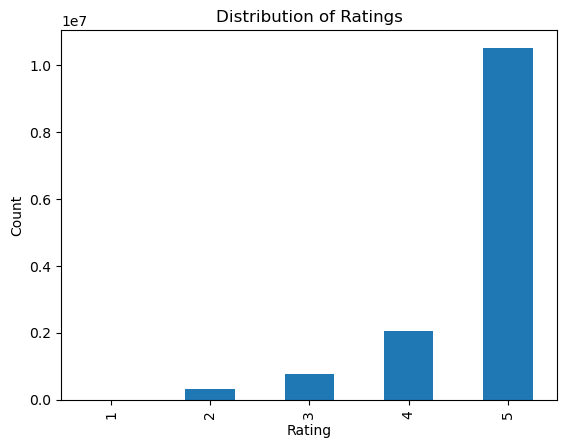

In [36]:
import matplotlib.pyplot as plt

ratings["RATING"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()